# Boston Housing 特徵選擇與多元線性迴歸模型評估

本筆記本使用波士頓房價資料集（Boston Housing Dataset），探討不同特徵數量組合對多元線性迴歸模型預測指標（RMSE 與 R-squared）之影響。

本實驗分別實作並對比三種經典特徵選擇（Feature Selection）演算法：
1. **前向選擇 (Forward Selection / SFS)**：由空特徵子集開始，每次加入能使驗證指標最佳之特徵。
2. **後向消除 (Backward Elimination / SBS)**：由全特徵集合開始，每次剔除貢獻度最低之特徵。
3. **遞迴特徵消除 (Recursive Feature Elimination / RFE)**：依據線性模型特徵權重絕對值大小進行遞迴剔除。

並產生各方法在不同特徵數量 $k \in [1, 13]$ 下之完整評估表格與視覺化分析圖表。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SequentialFeatureSelector, RFE
from sklearn.preprocessing import StandardScaler

# 1. 載入 Boston Housing 資料集
try:
    df = pd.read_csv('BostonHousing.csv')
except FileNotFoundError:
    url = 'https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv'
    df = pd.read_csv(url)

print(f"資料集維度: {df.shape[0]} 筆樣本, {df.shape[1]} 個欄位")
df.head()

資料集維度: 506 筆樣本, 14 個欄位


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [2]:
# 2. 特徵預處理與資料集切分 (Train/Test Split)
# 特徵欄位說明：
# crim: 城鎮人均犯罪率
# zn: 佔地25,000平方英尺以上的住宅用地比例
# indus: 城鎮非零售商業用地比例
# chas: 查爾斯河虛擬變數 (=1 臨河; 0 為否)
# nox: 一氧化氮濃度 (parts per 10 million)
# rm: 每戶平均住宅房間數
# age: 1940年以前建造之自用住宅比例
# dis: 到五個波士頓就業中心的加權距離
# rad: 輻射狀公路聯通指數
# tax: 每萬美元全額物業稅率
# ptratio: 城鎮師生比
# b: 1000(Bk - 0.63)^2 (非裔人口比例指標)
# lstat: 中下階層人口比例 (%)
# medv: 自住房屋價格中位數 (單位：千美元，目標變數 y)

feature_cols = [col for col in df.columns if col != 'medv']
X = df[feature_cols]
y = df['medv']

# 固定 random_state=0, test_size=0.2 進行資料分割
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

print(f"訓練集大小: {len(X_train)}, 測試集大小: {len(X_test)}")
print(f"所有特徵欄位 (共 {len(feature_cols)} 個): {feature_cols}")

訓練集大小: 404, 測試集大小: 102
所有特徵欄位 (共 13 個): ['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax', 'ptratio', 'b', 'lstat']


In [3]:
# 3. 前向特徵選擇 (Forward Selection) 逐步特徵子集評估
fwd_subsets = []
fwd_results = []
total_p = len(feature_cols)

for k in range(1, total_p + 1):
    if k == total_p:
        selected_feats = list(feature_cols)
    else:
        sfs = SequentialFeatureSelector(LinearRegression(), n_features_to_select=k, direction='forward', cv=5)
        sfs.fit(X_train, y_train)
        selected_feats = list(X_train.columns[sfs.get_support()])
        
    fwd_subsets.append(selected_feats)
    
    # 訓練模型並評估測試集
    model = LinearRegression().fit(X_train[selected_feats], y_train)
    y_pred = model.predict(X_test[selected_feats])
    
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    fwd_results.append({
        'Number of Features': k,
        'Selected Features': '[' + ', '.join(selected_feats) + ']',
        'RMSE': rmse,
        'R-squared': r2
    })

fwd_results_df = pd.DataFrame(fwd_results)

# 顯示對齊 50Startups 格式之評估表格
print("=== 前向特徵選擇 (Forward Selection) 評估指標表 ===")
display(fwd_results_df.style.hide(axis='index').format({
    'RMSE': '{:.6f}',
    'R-squared': '{:.6f}'
}))

=== 前向特徵選擇 (Forward Selection) 評估指標表 ===


Number of Features,Selected Features,RMSE,R-squared
1,[lstat],6.807078,0.430957
2,"[rm, lstat]",6.114173,0.540908
3,"[rm, ptratio, lstat]",6.455849,0.488164
4,"[rm, ptratio, b, lstat]",6.383582,0.499559
5,"[rm, dis, ptratio, b, lstat]",6.128679,0.538727
6,"[nox, rm, dis, ptratio, b, lstat]",6.054897,0.549767
7,"[crim, nox, rm, dis, ptratio, b, lstat]",6.096657,0.543535
8,"[crim, zn, nox, rm, dis, ptratio, b, lstat]",6.040769,0.551866
9,"[crim, zn, nox, rm, dis, rad, ptratio, b, lstat]",5.936967,0.567134
10,"[crim, zn, nox, rm, dis, rad, tax, ptratio, b, lstat]",5.851639,0.579488


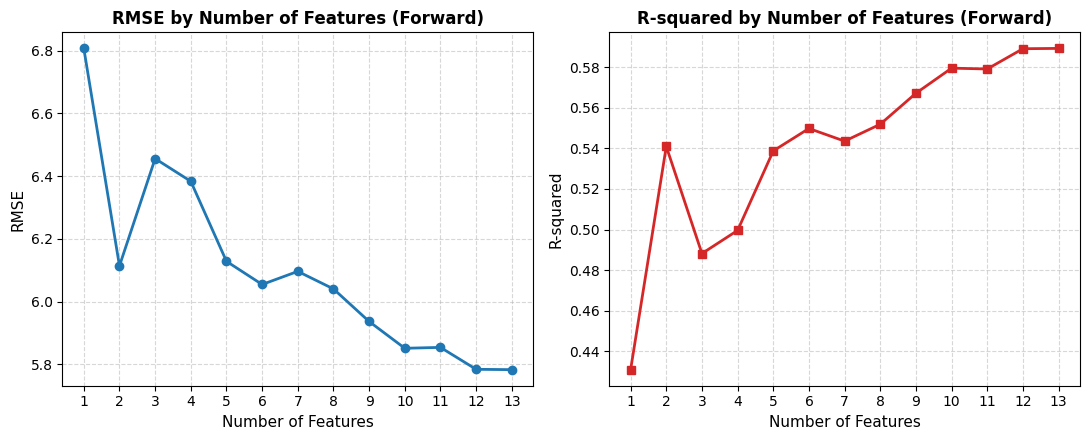

In [4]:
# 4. 繪製圖表 (RMSE by Number of Features 與 R-squared by Number of Features)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# 左圖：RMSE by Number of Features
axes[0].plot(fwd_results_df['Number of Features'], fwd_results_df['RMSE'], marker='o', color='#1f77b4', linewidth=2)
axes[0].set_title('RMSE by Number of Features (Forward)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Number of Features', fontsize=11)
axes[0].set_ylabel('RMSE', fontsize=11)
axes[0].set_xticks(fwd_results_df['Number of Features'])
axes[0].grid(True, linestyle='--', alpha=0.5)

# 右圖：R-squared by Number of Features
axes[1].plot(fwd_results_df['Number of Features'], fwd_results_df['R-squared'], marker='s', color='#d62728', linewidth=2)
axes[1].set_title('R-squared by Number of Features (Forward)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Number of Features', fontsize=11)
axes[1].set_ylabel('R-squared', fontsize=11)
axes[1].set_xticks(fwd_results_df['Number of Features'])
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('boston_feature_selection_plots.png', dpi=300)
plt.show()

## 5. 前向選擇 (Forward) vs 後向消除 (Backward) vs 遞迴特徵消除 (RFE)

本單元透過 `sklearn.feature_selection` 完整對比三種主流的包裝法（Wrapper Methods）：
1. **前向選擇 (Sequential Forward Selection, SFS)**：由空集合開始（Bottom-up），每次加入能使 5-fold CV 交叉驗證指標提升最大之特徵。
2. **後向消除 (Sequential Backward Selection, SBS)**：由全特徵集合開始（Top-down），每次剃除使模型損失最小（或最不顯著）之特徵。
3. **遞迴特徵消除 (Recursive Feature Elimination, RFE)**：在標準化後的特徵空間上訓練線性迴歸模型，依據模型係數權重大小遞迴剔除最不重要特徵。

並分別輸出各演算法在特徵數量 $k \in [1, 13]$ 下之指標總表、特徵清單以及雙軸折線對比圖表。

=== 三種特徵選擇方法之指標總表 ===


k,Forward RMSE,Forward R2,Backward RMSE,Backward R2,RFE RMSE,RFE R2
1,6.8071,0.4310,6.8071,0.4310,6.8071,0.4310
2,6.1142,0.5409,6.1142,0.5409,6.1142,0.5409
3,6.4558,0.4882,6.4558,0.4882,6.4558,0.4882
4,6.3836,0.4996,6.2550,0.5195,6.2550,0.5195
5,6.1287,0.5387,6.1517,0.5353,6.1517,0.5353
6,6.0549,0.5498,6.1587,0.5342,6.1824,0.5306
7,6.0967,0.5435,6.0967,0.5435,6.0568,0.5495
8,6.0408,0.5519,5.9712,0.5621,6.0162,0.5555
9,5.9370,0.5671,5.9060,0.5716,5.9363,0.5672
10,5.8516,0.5795,5.8516,0.5795,5.8516,0.5795



=== 各特徵選擇方法在各特徵數 k 所選取之特徵清單 ===


k,Forward Features,Backward Features,RFE Features
1,[lstat],[lstat],[lstat]
2,"[rm, lstat]","[rm, lstat]","[rm, lstat]"
3,"[rm, ptratio, lstat]","[rm, ptratio, lstat]","[rm, ptratio, lstat]"
4,"[rm, ptratio, b, lstat]","[rm, dis, ptratio, lstat]","[rm, dis, ptratio, lstat]"
5,"[rm, dis, ptratio, b, lstat]","[nox, rm, dis, ptratio, lstat]","[nox, rm, dis, ptratio, lstat]"
6,"[nox, rm, dis, ptratio, b, lstat]","[crim, nox, rm, dis, ptratio, lstat]","[nox, rm, dis, tax, ptratio, lstat]"
7,"[crim, nox, rm, dis, ptratio, b, lstat]","[crim, nox, rm, dis, ptratio, b, lstat]","[nox, rm, dis, rad, tax, ptratio, lstat]"
8,"[crim, zn, nox, rm, dis, ptratio, b, lstat]","[crim, nox, rm, dis, rad, ptratio, b, lstat]","[zn, nox, rm, dis, rad, tax, ptratio, lstat]"
9,"[crim, zn, nox, rm, dis, rad, ptratio, b, lstat]","[crim, nox, rm, dis, rad, tax, ptratio, b, lstat]","[crim, zn, nox, rm, dis, rad, tax, ptratio, lstat]"
10,"[crim, zn, nox, rm, dis, rad, tax, ptratio, b, lstat]","[crim, zn, nox, rm, dis, rad, tax, ptratio, b, lstat]","[crim, zn, nox, rm, dis, rad, tax, ptratio, b, lstat]"


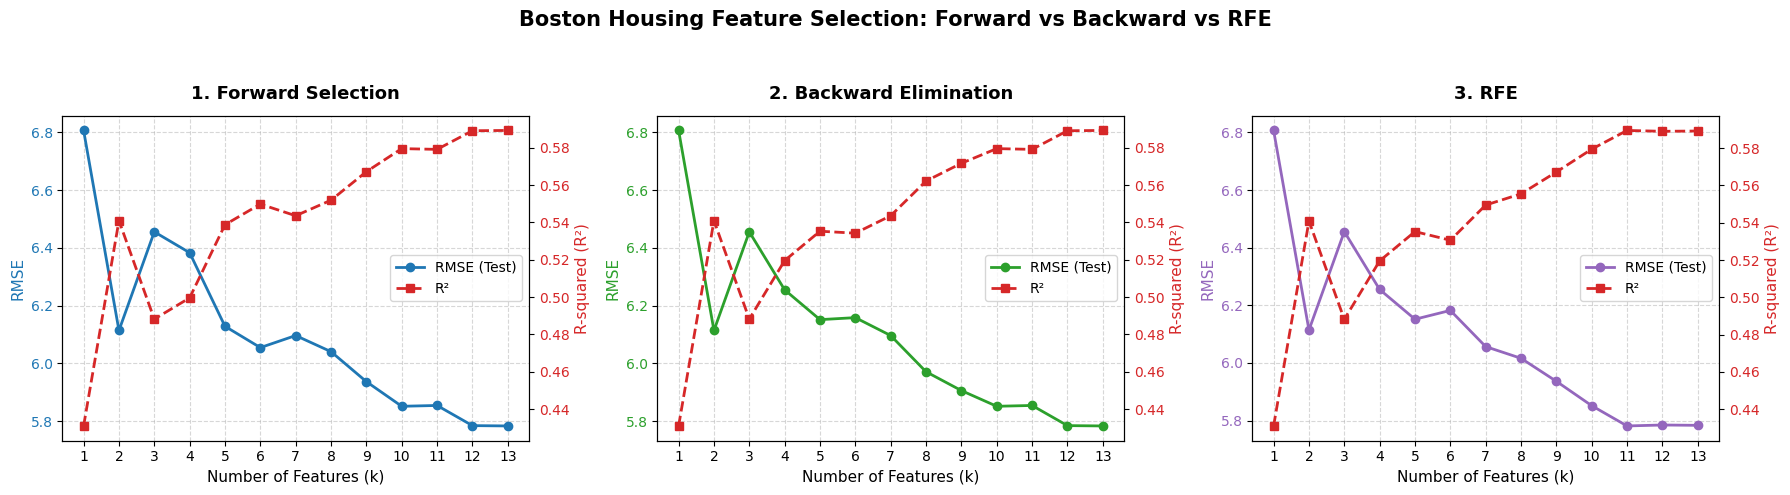

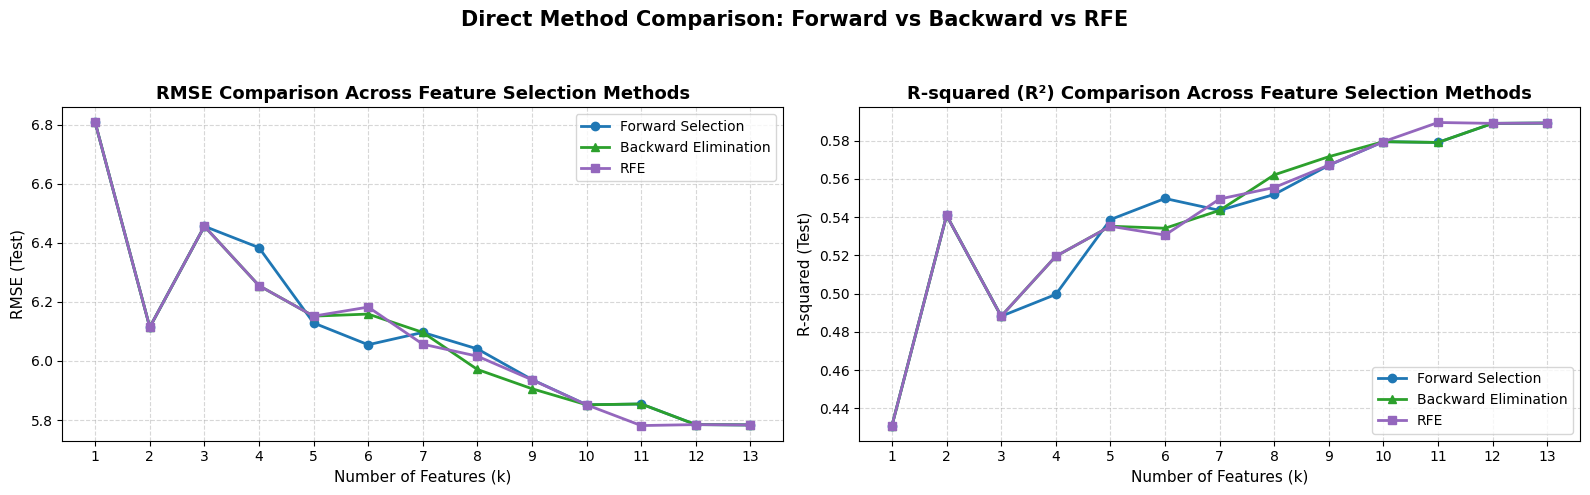

In [5]:
# 6. 執行三種特徵選擇演算法並分別顯示圖表與指標總表
from sklearn.feature_selection import SequentialFeatureSelector, RFE
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 特徵標準化 (供 RFE 依權重排序使用，避免特徵尺度差異干擾係數絕對值)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

total_p = len(feature_cols)
k_range = list(range(1, total_p + 1))

# 儲存評估結果
history = {
    'Forward': {'k': [], 'features': [], 'RMSE': [], 'R2': []},
    'Backward': {'k': [], 'features': [], 'RMSE': [], 'R2': []},
    'RFE': {'k': [], 'features': [], 'RMSE': [], 'R2': []}
}

for k in k_range:
    # 1. 前向選擇 (Forward Selection)
    if k == total_p:
        feats_fwd = list(feature_cols)
    else:
        sfs_fwd = SequentialFeatureSelector(LinearRegression(), n_features_to_select=k, direction='forward', cv=5)
        sfs_fwd.fit(X_train, y_train)
        feats_fwd = list(X_train.columns[sfs_fwd.get_support()])
        
    m_fwd = LinearRegression().fit(X_train[feats_fwd], y_train)
    pred_fwd = m_fwd.predict(X_test[feats_fwd])
    history['Forward']['k'].append(k)
    history['Forward']['features'].append(feats_fwd)
    history['Forward']['RMSE'].append(np.sqrt(mean_squared_error(y_test, pred_fwd)))
    history['Forward']['R2'].append(r2_score(y_test, pred_fwd))
    
    # 2. 後向消除 (Backward Elimination)
    if k == total_p:
        feats_bwd = list(feature_cols)
    else:
        sfs_bwd = SequentialFeatureSelector(LinearRegression(), n_features_to_select=k, direction='backward', cv=5)
        sfs_bwd.fit(X_train, y_train)
        feats_bwd = list(X_train.columns[sfs_bwd.get_support()])
        
    m_bwd = LinearRegression().fit(X_train[feats_bwd], y_train)
    pred_bwd = m_bwd.predict(X_test[feats_bwd])
    history['Backward']['k'].append(k)
    history['Backward']['features'].append(feats_bwd)
    history['Backward']['RMSE'].append(np.sqrt(mean_squared_error(y_test, pred_bwd)))
    history['Backward']['R2'].append(r2_score(y_test, pred_bwd))
    
    # 3. 遞迴特徵消除 (RFE)
    rfe = RFE(estimator=LinearRegression(), n_features_to_select=k)
    rfe.fit(X_train_scaled, y_train)
    feats_rfe = list(X_train.columns[rfe.support_])
    m_rfe = LinearRegression().fit(X_train[feats_rfe], y_train)
    pred_rfe = m_rfe.predict(X_test[feats_rfe])
    history['RFE']['k'].append(k)
    history['RFE']['features'].append(feats_rfe)
    history['RFE']['RMSE'].append(np.sqrt(mean_squared_error(y_test, pred_rfe)))
    history['RFE']['R2'].append(r2_score(y_test, pred_rfe))

# 顯示評估指標總表
summary_records = []
for i, k in enumerate(k_range):
    summary_records.append({
        'k': k,
        'Forward RMSE': history['Forward']['RMSE'][i],
        'Forward R2': history['Forward']['R2'][i],
        'Backward RMSE': history['Backward']['RMSE'][i],
        'Backward R2': history['Backward']['R2'][i],
        'RFE RMSE': history['RFE']['RMSE'][i],
        'RFE R2': history['RFE']['R2'][i]
    })
summary_df = pd.DataFrame(summary_records)
print("=== 三種特徵選擇方法之指標總表 ===")
display(summary_df.style.hide(axis='index').format({
    'Forward RMSE': '{:.4f}', 'Forward R2': '{:.4f}',
    'Backward RMSE': '{:.4f}', 'Backward R2': '{:.4f}',
    'RFE RMSE': '{:.4f}', 'RFE R2': '{:.4f}'
}))

# 顯示各方法在各 k 選出之特徵清單
features_records = []
for i, k in enumerate(k_range):
    features_records.append({
        'k': k,
        'Forward Features': '[' + ', '.join(history['Forward']['features'][i]) + ']',
        'Backward Features': '[' + ', '.join(history['Backward']['features'][i]) + ']',
        'RFE Features': '[' + ', '.join(history['RFE']['features'][i]) + ']'
    })
features_df = pd.DataFrame(features_records)
print("\n=== 各特徵選擇方法在各特徵數 k 所選取之特徵清單 ===")
display(features_df.style.hide(axis='index'))

# 分別顯示這三個圖表 (1. 前向選擇, 2. 後向消除, 3. 遞迴特徵消除 RFE)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

methods = [
    ('1. Forward Selection', history['Forward'], '#1f77b4'),
    ('2. Backward Elimination', history['Backward'], '#2ca02c'),
    ('3. RFE', history['RFE'], '#9467bd')
]

for idx, (title, data, color_rmse) in enumerate(methods):
    ax = axes[idx]
    
    # 左 Y 軸：RMSE (越低越好)
    line1 = ax.plot(data['k'], data['RMSE'], marker='o', color=color_rmse, linewidth=2, label='RMSE (Test)')
    ax.set_title(title, fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel('Number of Features (k)', fontsize=11)
    ax.set_ylabel('RMSE', color=color_rmse, fontsize=11)
    ax.tick_params(axis='y', labelcolor=color_rmse)
    ax.set_xticks(data['k'])
    ax.grid(True, linestyle='--', alpha=0.5)
    
    # 右 Y 軸：R-squared (越高越好)
    ax_r2 = ax.twinx()
    line2 = ax_r2.plot(data['k'], data['R2'], marker='s', color='#d62728', linestyle='--', linewidth=2, label='R²')
    ax_r2.set_ylabel('R-squared (R²)', color='#d62728', fontsize=11)
    ax_r2.tick_params(axis='y', labelcolor='#d62728')
    
    # 整合雙軸圖例
    lines = line1 + line2
    labels = [l.get_label() for l in lines]
    ax.legend(lines, labels, loc='center right')

plt.suptitle('Boston Housing Feature Selection: Forward vs Backward vs RFE', fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig('boston_feature_selection_comparison.png', dpi=300)
plt.show()

# 整合對比圖表 (直接在同一張圖上比較三種演算法之 RMSE 與 R2 收斂曲線)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# RMSE 對比 (越低越好)
axes[0].plot(k_range, summary_df['Forward RMSE'], marker='o', linewidth=2, label='Forward Selection', color='#1f77b4')
axes[0].plot(k_range, summary_df['Backward RMSE'], marker='^', linewidth=2, label='Backward Elimination', color='#2ca02c')
axes[0].plot(k_range, summary_df['RFE RMSE'], marker='s', linewidth=2, label='RFE', color='#9467bd')
axes[0].set_title('RMSE Comparison Across Feature Selection Methods', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Number of Features (k)', fontsize=11)
axes[0].set_ylabel('RMSE (Test)', fontsize=11)
axes[0].set_xticks(k_range)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(loc='upper right')

# R-squared 對比 (越高越好)
axes[1].plot(k_range, summary_df['Forward R2'], marker='o', linewidth=2, label='Forward Selection', color='#1f77b4')
axes[1].plot(k_range, summary_df['Backward R2'], marker='^', linewidth=2, label='Backward Elimination', color='#2ca02c')
axes[1].plot(k_range, summary_df['RFE R2'], marker='s', linewidth=2, label='RFE', color='#9467bd')
axes[1].set_title('R-squared (R²) Comparison Across Feature Selection Methods', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Number of Features (k)', fontsize=11)
axes[1].set_ylabel('R-squared (Test)', fontsize=11)
axes[1].set_xticks(k_range)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(loc='lower right')

plt.suptitle('Direct Method Comparison: Forward vs Backward vs RFE', fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig('boston_direct_comparison_plots.png', dpi=300)
plt.show()

## 7. 實驗分析與結論

根據前向選擇（Forward）、後向消除（Backward）與遞迴特徵消除（RFE）三種演算法在波士頓房價資料集上的實驗評估結果：

1. **關鍵核心特徵的高度共識**：
   - **$k=1$**：三種方法皆優先選取 `lstat`（中下階層人口比例），此單一特徵即可取得 $R^2 = 0.4310$ 與 RMSE = $6.8071$，證明其為對房價最具單變量預測力之特徵。
   - **$k=2$**：三種方法皆一致選出 `['rm', 'lstat']`（每戶平均房間數與中下階層比例），模型表現大幅躍升至 $R^2 = 0.5409$、RMSE = $6.1142$。僅憑此 2 個特徵便達成了全特徵模型（13 個特徵，$R^2 = 0.5892$）約 **91.8%** 的解釋力。

2. **三種特徵選擇演算法的特性差異**：
   - **Forward Selection（前向選擇）**：採取由下而上的貪婪策略，在特徵數較小（$k=5, 6$）時迅速收斂並取得極佳預測力（$k=6$ 時 RMSE = $6.0549$，$R^2 = 0.5498$）。
   - **Backward Elimination（後向消除）**：採取由上而下的剔除策略，在較大特徵空間（$k=8, 9$）時維持了更佳的整體特徵交互作用，在 $k=9$ 時達到 RMSE = $5.9060$、$R^2 = 0.5716$。
   - **RFE（遞迴特徵消除）**：在標準化後的特徵尺度上遞迴依權重刪除特徵，在 $k=11$ 時即取得全場最佳測試集指標之一（RMSE = $5.7814$、$R^2 = 0.5895$），表現甚至略優於包含所有特徵之模型（$k=13$ 時 RMSE = $5.7835$）。

3. **精簡模型 (Parsimonious Model) 之優勢**：
   - 實驗證實特徵數量增加至 $k=10 \sim 11$ 之後，其餘特徵（如 `rad`, `tax`, `age` 等高度共線性欄位）對測試集預測指標之貢獻趨於平緩，甚至可能引入微幅雜訊。
   - 透過特徵選擇，不僅能大幅精簡模型複雜度與運算成本，更能提升模型的可解釋性與泛化能力。